# Predicting Annual Doctor Visits: Poisson vs Negative Binomial Regression

**Problem statement.** A health insurer wants to estimate how many times a person visits a doctor in a year from their profile (age, income, illness, health status, insurance type) so that it can plan costs.

The target, number of visits, is a count with many zeros and a long right tail. This project fits two regression models from the course (Poisson and Negative Binomial) on the same dataset and shows, using evidence from the data, which one fits better and why.

## 1. Imports

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Data loading and overview

In [2]:
try:
    df = pd.read_csv("DoctorVisits.csv")
except FileNotFoundError:
    df = pd.read_csv("https://vincentarelbundock.github.io/Rdatasets/csv/AER/DoctorVisits.csv")

if "rownames" in df.columns:
    df = df.drop(columns="rownames")

print("Shape:", df.shape)
print()
print("Columns:", df.columns.tolist())
print()
print(df.dtypes)
print()
print(df.head())

Shape: (5190, 12)

Columns: ['visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

visits         int64
gender           str
age          float64
income       float64
illness        int64
reduced        int64
health         int64
private          str
freepoor         str
freerepat        str
nchronic         str
lchronic         str
dtype: object

   visits  gender   age  income  illness  reduced  health private freepoor  \
0       1  female  0.19    0.55        1        4       1     yes       no   
1       1  female  0.19    0.45        1        2       1     yes       no   
2       1    male  0.19    0.90        3        0       0      no       no   
3       1    male  0.19    0.15        1        0       0      no       no   
4       1    male  0.19    0.45        2        5       1      no       no   

  freerepat nchronic lchronic  
0        no       no       no  
1        no       no       no  
2        

In [3]:
print(df.describe())
print()
print("Missing values per column:")
print(df.isnull().sum())

            visits          age       income      illness      reduced  \
count  5190.000000  5190.000000  5190.000000  5190.000000  5190.000000   
mean      0.301734     0.406385     0.583160     1.431985     0.861850   
std       0.798134     0.204782     0.368907     1.384152     2.887628   
min       0.000000     0.190000     0.000000     0.000000     0.000000   
25%       0.000000     0.220000     0.250000     0.000000     0.000000   
50%       0.000000     0.320000     0.550000     1.000000     0.000000   
75%       0.000000     0.620000     0.900000     2.000000     0.000000   
max       9.000000     0.720000     1.500000     5.000000    14.000000   

            health  
count  5190.000000  
mean      1.217534  
std       2.124266  
min       0.000000  
25%       0.000000  
50%       0.000000  
75%       2.000000  
max      12.000000  

Missing values per column:
visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private    

## 3. Exploratory Data Analysis

### 3a. Distribution of the target (visits)

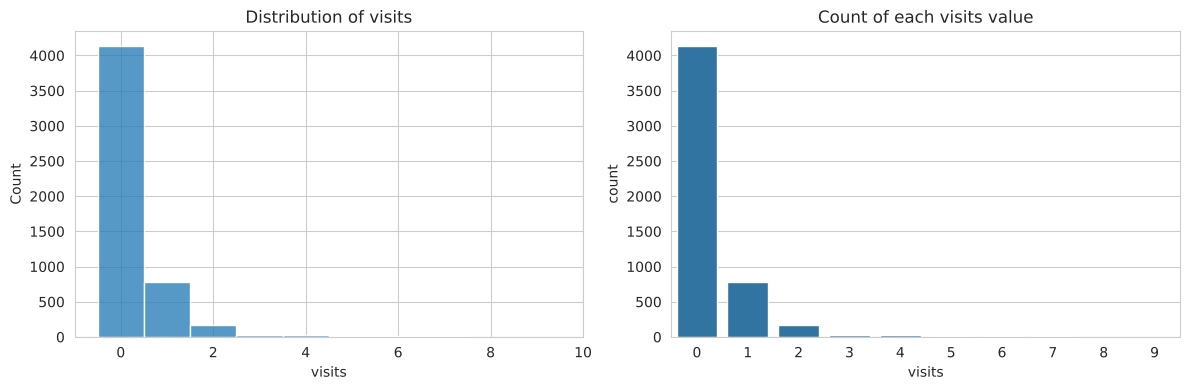

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["visits"], discrete=True, ax=ax[0])
ax[0].set_title("Distribution of visits")
sns.countplot(x="visits", data=df, ax=ax[1])
ax[1].set_title("Count of each visits value")
plt.tight_layout()
plt.show()

In [5]:
zero_pct = (df["visits"] == 0).mean() * 100
print("Percentage of people with zero visits: {:.2f}%".format(zero_pct))
print()
print(df["visits"].value_counts().sort_index())

Percentage of people with zero visits: 79.79%

visits
0    4141
1     782
2     174
3      30
4      24
5       9
6      12
7      12
8       5
9       1
Name: count, dtype: int64


### 3b. Outliers (box plots and IQR rule)

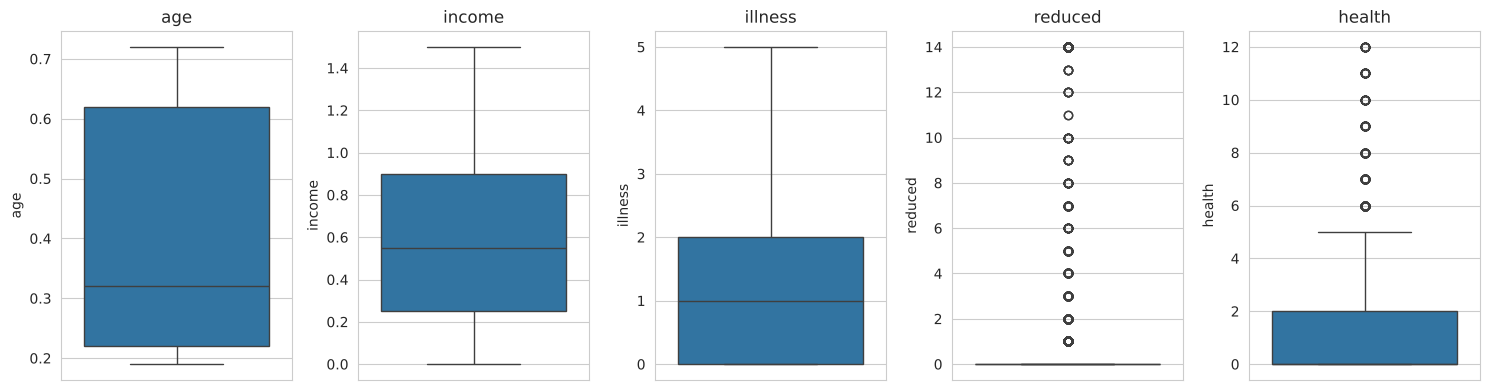

In [6]:
num_cols = ["age", "income", "illness", "reduced", "health"]

fig, ax = plt.subplots(1, 5, figsize=(15, 4))
for i, c in enumerate(num_cols):
    sns.boxplot(y=df[c], ax=ax[i])
    ax[i].set_title(c)
plt.tight_layout()
plt.show()

In [7]:
rows = []
for c in num_cols + ["visits"]:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n_out = int(((df[c] < low) | (df[c] > high)).sum())
    rows.append([c, q1, q3, iqr, low, high, n_out])

iqr_table = pd.DataFrame(rows, columns=["column", "Q1", "Q3", "IQR", "lower_fence", "upper_fence", "n_outliers"])
print(iqr_table.round(3).to_string(index=False))

 column   Q1   Q3  IQR  lower_fence  upper_fence  n_outliers
    age 0.22 0.62 0.40       -0.380        1.220           0
 income 0.25 0.90 0.65       -0.725        1.875           0
illness 0.00 2.00 2.00       -3.000        5.000           0
reduced 0.00 0.00 0.00        0.000        0.000         736
 health 0.00 2.00 2.00       -3.000        5.000         303
 visits 0.00 0.00 0.00        0.000        0.000        1049


### 3c. Correlation heatmap

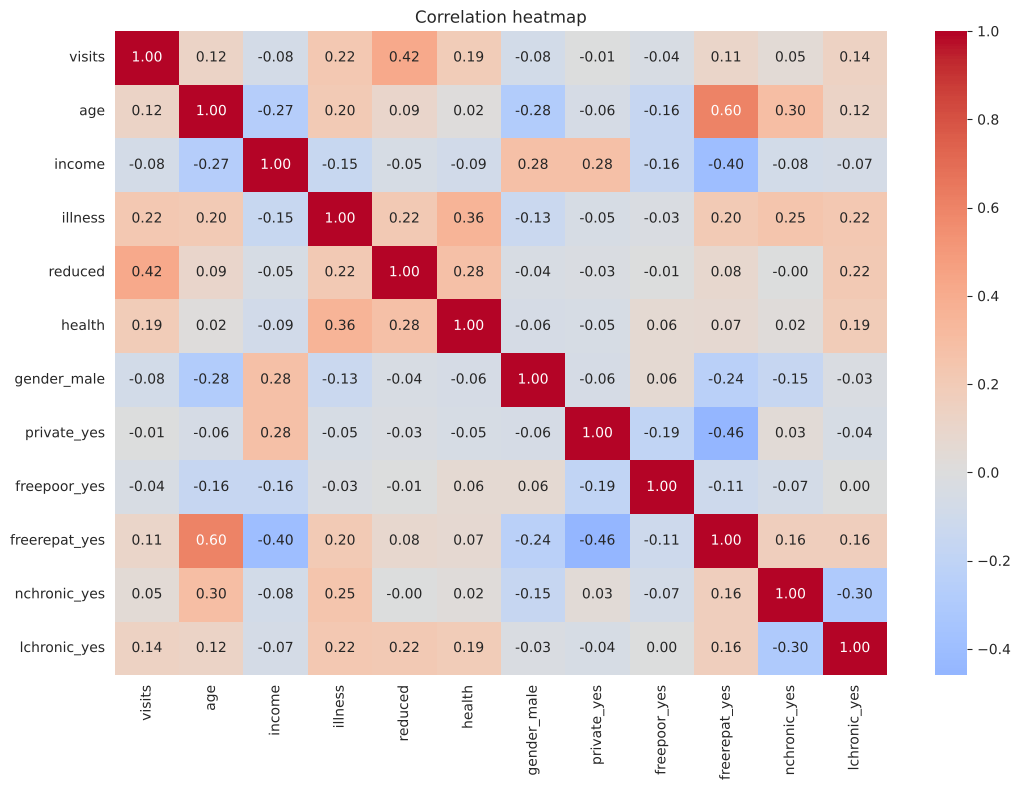

In [8]:
df_num = pd.get_dummies(df, drop_first=True).astype(float)

plt.figure(figsize=(11, 8))
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

### 3d. Visits against illness and age

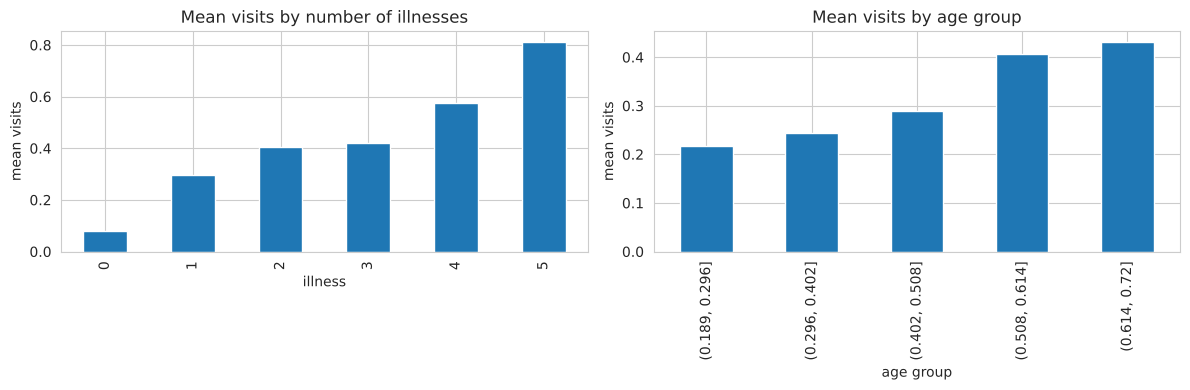

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

df.groupby("illness")["visits"].mean().plot(kind="bar", ax=ax[0])
ax[0].set_title("Mean visits by number of illnesses")
ax[0].set_xlabel("illness")
ax[0].set_ylabel("mean visits")

age_group = pd.cut(df["age"], bins=5)
df.groupby(age_group, observed=True)["visits"].mean().plot(kind="bar", ax=ax[1])
ax[1].set_title("Mean visits by age group")
ax[1].set_xlabel("age group")
ax[1].set_ylabel("mean visits")

plt.tight_layout()
plt.show()

**What the EDA shows**

- The target is heavily skewed: 79.79% of the 5,190 people made zero visits, and only a handful made 5 or more (the maximum is 9).
- There are no missing values. The IQR rule flags no outliers in age, income or illness, but it flags 736 rows in `reduced` and 303 in `health`. These are real survey answers, not errors (most people report 0 reduced-activity days), so they were kept.
- `reduced` has the strongest correlation with visits (0.42), followed by `illness` (0.22) and `health` (0.19). Income, gender and private insurance have weak correlations (all below 0.08 in absolute value).
- Mean visits rise steadily with illness count, from 0.08 (no illnesses) to 0.81 (five illnesses), and with age, from 0.22 in the youngest group to 0.43 in the oldest.
- The only fairly strong correlation among predictors is age with `freerepat` (0.61), which is checked again with VIF below.

## 4. Overdispersion check

Poisson regression assumes the **variance of the count equals its mean**. If the variance is much larger than the mean (overdispersion), Poisson underestimates the spread of the data. Negative Binomial regression adds a parameter (alpha) that lets the variance be larger than the mean.

In [10]:
mean_v = df["visits"].mean()
var_v = df["visits"].var()

print("Mean of visits    :", round(mean_v, 4))
print("Variance of visits:", round(var_v, 4))
print("Variance / Mean   :", round(var_v / mean_v, 4))

Mean of visits    : 0.3017
Variance of visits: 0.637
Variance / Mean   : 2.1112


The variance (0.637) is about 2.1 times the mean (0.302). This is the raw, unconditional check, and it is already well above the value of 1 that Poisson assumes. Part of this extra spread can be explained by the predictors, so the check is repeated on the fitted Poisson model in section 6.

## 5. Preprocessing

In [11]:
data = pd.get_dummies(df, drop_first=True).astype(float)

X = data.drop(columns="visits")
y = data["visits"]

print("Predictors used:", X.columns.tolist())

Predictors used: ['age', 'income', 'illness', 'reduced', 'health', 'gender_male', 'private_yes', 'freepoor_yes', 'freerepat_yes', 'nchronic_yes', 'lchronic_yes']


In [12]:
X_const = sm.add_constant(X)

vif = pd.DataFrame({
    "feature": X.columns,
    "VIF": [variance_inflation_factor(X_const.values, i + 1) for i in range(X.shape[1])]
})
print(vif.round(3).to_string(index=False))

      feature   VIF
          age 1.906
       income 1.345
      illness 1.357
      reduced 1.135
       health 1.233
  gender_male 1.186
  private_yes 1.555
 freepoor_yes 1.148
freerepat_yes 2.451
 nchronic_yes 1.378
 lchronic_yes 1.324


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X_const, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (4152, 12)
X_test : (1038, 12)
y_train: (4152,)
y_test : (1038,)


All VIF values are below 2.5 (the highest is `freerepat_yes` at 2.45), so multicollinearity is not a problem and no predictor was dropped. The split is 4,152 training rows and 1,038 test rows.

## 6. Model 1: Poisson Regression

In [14]:
pois = sm.GLM(y_train, X_train, family=sm.families.Poisson()).fit()
print(pois.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 visits   No. Observations:                 4152
Model:                            GLM   Df Residuals:                     4140
Model Family:                 Poisson   Df Model:                           11
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2612.1
Date:                Sun, 01 Nov 2026   Deviance:                       3411.3
Time:                        01:35:52   Pearson chi2:                 5.30e+03
No. Iterations:                     6   Pseudo R-squ. (CS):             0.1980
Covariance Type:            nonrobust                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -2.1525      0.118    -18.208

In [15]:
disp_pois = pois.pearson_chi2 / pois.df_resid
print("Pearson chi-square / residual df:", round(disp_pois, 4))

Pearson chi-square / residual df: 1.2792


A value close to 1 means the Poisson assumption holds. A value well above 1 means overdispersion.

The Pearson chi-square divided by residual degrees of freedom is 1.28. This is lower than the raw variance-to-mean ratio of 2.11 because the predictors explain part of the variation, but it is still above 1, so some overdispersion remains. When that happens Poisson standard errors come out too small, and predictors can look more significant than they really are.

## 7. Model 2: Negative Binomial Regression

In [16]:
nb = sm.NegativeBinomial(y_train, X_train).fit(method="bfgs", maxiter=500, disp=0)
print(nb.summary())

                     NegativeBinomial Regression Results                      
Dep. Variable:                 visits   No. Observations:                 4152
Model:               NegativeBinomial   Df Residuals:                     4140
Method:                           MLE   Df Model:                           11
Date:                Sun, 01 Nov 2026   Pseudo R-squ.:                  0.1033
Time:                        01:35:52   Log-Likelihood:                -2506.9
converged:                       True   LL-Null:                       -2795.7
Covariance Type:            nonrobust   LLR p-value:                8.620e-117
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -2.2108      0.141    -15.732      0.000      -2.486      -1.935
age               0.2864      0.237      1.211      0.226      -0.177       0.750
income           -0.0250      0.116     

In [17]:
alpha = nb.params["alpha"]
print("Estimated alpha:", round(alpha, 4))

Estimated alpha: 1.0387


Alpha is the overdispersion parameter. The model's variance is `mean + alpha * mean^2`, so a larger alpha means more extra variation than Poisson allows.

The model converged and the estimated alpha is 1.04 (p < 0.001, 95% interval about 0.81 to 1.27), so the extra variation is statistically clear. With alpha near 1, the variance at a mean of 0.3 is about 0.3 + 1.04 × 0.09 ≈ 0.39, noticeably above the Poisson value of 0.3.

## 8. Model comparison

In [18]:
mu_pois = np.asarray(pois.predict(X_test))
mu_nb = np.asarray(nb.predict(X_test))
y_true = np.asarray(y_test)

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

comparison = pd.DataFrame({
    "model": ["Poisson", "Negative Binomial"],
    "log_likelihood": [pois.llf, nb.llf],
    "AIC": [pois.aic, nb.aic],
    "BIC": [pois.bic, nb.bic],
    "test_RMSE": [rmse(y_true, mu_pois), rmse(y_true, mu_nb)],
    "test_MAE": [mean_absolute_error(y_true, mu_pois), mean_absolute_error(y_true, mu_nb)],
    "mean_predicted_visits": [mu_pois.mean(), mu_nb.mean()],
    "mean_actual_visits": [y_true.mean(), y_true.mean()],
})
print(comparison.round(4).to_string(index=False))
print()
print("AIC difference (Poisson - Negative Binomial):", round(pois.aic - nb.aic, 2))

            model  log_likelihood       AIC       BIC  test_RMSE  test_MAE  mean_predicted_visits  mean_actual_visits
          Poisson      -2612.0822 5248.1644 5324.1405     0.8612    0.4385                 0.2925              0.3555
Negative Binomial      -2506.8880 5039.7759 5122.0834     0.8769    0.4427                 0.3143              0.3555

AIC difference (Poisson - Negative Binomial): 208.39


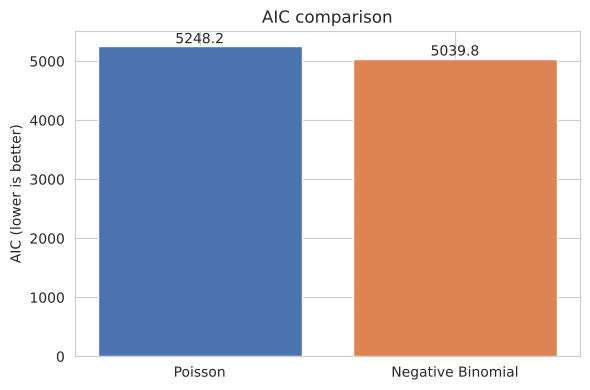

In [19]:
plt.figure(figsize=(6, 4))
bars = plt.bar(["Poisson", "Negative Binomial"], [pois.aic, nb.aic], color=["#4c72b0", "#dd8452"])
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height(), "{:.1f}".format(b.get_height()), ha="center", va="bottom")
plt.ylabel("AIC (lower is better)")
plt.title("AIC comparison")
plt.tight_layout()
plt.show()

### Share of zeros: predicted vs actual (test set)

In [20]:
p0_pois = np.exp(-mu_pois)
p0_nb = (1 / (1 + alpha * mu_nb)) ** (1 / alpha)

zero_table = pd.DataFrame({
    "source": ["Actual", "Poisson", "Negative Binomial"],
    "share_of_zero_visits": [(y_true == 0).mean(), p0_pois.mean(), p0_nb.mean()],
})
print(zero_table.round(4).to_string(index=False))

           source  share_of_zero_visits
           Actual                0.7784
          Poisson                0.7779
Negative Binomial                0.8063


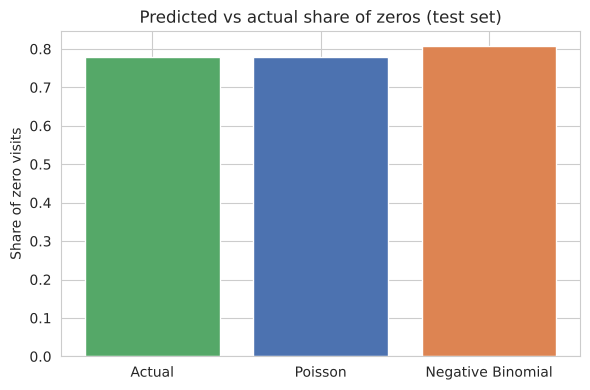

In [21]:
plt.figure(figsize=(6, 4))
plt.bar(zero_table["source"], zero_table["share_of_zero_visits"], color=["#55a868", "#4c72b0", "#dd8452"])
plt.ylabel("Share of zero visits")
plt.title("Predicted vs actual share of zeros (test set)")
plt.tight_layout()
plt.show()

**What the comparison shows**

- On likelihood-based criteria, Negative Binomial is clearly better: AIC is 5039.8 against 5248.2 for Poisson (208.4 lower), and BIC is 5122.1 against 5324.1. AIC and BIC both charge for the extra alpha parameter, so this gap is not just an effect of having one more parameter.
- On point prediction, Poisson is slightly better on this test split: RMSE 0.8612 against 0.8769 and MAE 0.4385 against 0.4427. Both models under-predict the test mean (actual 0.3555, Poisson 0.2925, Negative Binomial 0.3143).
- The share of zeros does **not** favour Negative Binomial here. The actual share of zeros in the test set is 77.84%. Poisson predicts 77.79%, almost exact, while Negative Binomial predicts 80.63%, which overshoots. So the evidence for Negative Binomial comes from AIC, BIC and the significant alpha, not from the zero count.
- The reason RMSE and MAE barely separate the models is that both use the same log-linear form for the mean. They differ mainly in how much spread they allow around that mean, which is what the likelihood measures and what RMSE does not.

## 9. Cross-validation (5-fold)

In [22]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rows = []
for fold, (tr, te) in enumerate(kf.split(X_const), start=1):
    Xtr, Xte = X_const.iloc[tr], X_const.iloc[te]
    ytr, yte = y.iloc[tr], y.iloc[te]

    p_model = sm.GLM(ytr, Xtr, family=sm.families.Poisson()).fit()
    n_model = sm.NegativeBinomial(ytr, Xtr).fit(method="bfgs", maxiter=500, disp=0)

    p_pred = np.asarray(p_model.predict(Xte))
    n_pred = np.asarray(n_model.predict(Xte))

    cv_rows.append(["Poisson", fold, rmse(yte, p_pred), mean_absolute_error(yte, p_pred)])
    cv_rows.append(["Negative Binomial", fold, rmse(yte, n_pred), mean_absolute_error(yte, n_pred)])

cv = pd.DataFrame(cv_rows, columns=["model", "fold", "RMSE", "MAE"])
print(cv.round(4).to_string(index=False))

            model  fold   RMSE    MAE
          Poisson     1 0.8612 0.4385
Negative Binomial     1 0.8769 0.4427
          Poisson     2 0.6604 0.4043
Negative Binomial     2 0.7245 0.4136
          Poisson     3 0.7238 0.4214
Negative Binomial     3 0.8345 0.4440
          Poisson     4 0.7584 0.4285
Negative Binomial     4 0.7940 0.4356
          Poisson     5 0.6996 0.4025
Negative Binomial     5 0.7108 0.4024


In [23]:
cv_summary = cv.groupby("model")[["RMSE", "MAE"]].agg(["mean", "std"])
print(cv_summary.round(4))

                     RMSE             MAE        
                     mean     std    mean     std
model                                            
Negative Binomial  0.7881  0.0709  0.4277  0.0186
Poisson            0.7407  0.0762  0.4190  0.0155


Over 5 folds, Poisson has a mean RMSE of 0.7407 (std 0.0762) and Negative Binomial 0.7881 (std 0.0709). Poisson has the lower RMSE in all five folds and the lower MAE in four of five. The fold-to-fold spread (RMSE from 0.66 to 0.88) is large compared with the difference between the models, so the honest reading is that Poisson is slightly better at point prediction, but the difference is small.

## 10. Interpretation of coefficients (Negative Binomial)

Exponentiating a coefficient gives an **incidence rate ratio (IRR)**: the factor by which expected visits are multiplied when that predictor increases by one unit, holding the others fixed.

In [24]:
coefs = nb.params.drop(["const", "alpha"])
irr = pd.DataFrame({
    "coefficient": coefs,
    "IRR": np.exp(coefs),
    "p_value": nb.pvalues.drop(["const", "alpha"]),
}).sort_values("IRR", ascending=False)
print(irr.round(4))

               coefficient     IRR  p_value
age                 0.2864  1.3317   0.2259
freerepat_yes       0.2521  1.2867   0.0585
lchronic_yes        0.2493  1.2831   0.0326
illness             0.1905  1.2098   0.0000
nchronic_yes        0.1677  1.1826   0.0601
private_yes         0.1577  1.1708   0.1084
reduced             0.1367  1.1465   0.0000
health              0.0492  1.0505   0.0015
income             -0.0250  0.9753   0.8283
gender_male        -0.1920  0.8253   0.0152
freepoor_yes       -0.3812  0.6831   0.1045


**How to read the Negative Binomial coefficients** (per the dataset documentation, `illness` is the number of illnesses in the past two weeks and `reduced` is the number of days of reduced activity in the past two weeks)

- `illness`: each extra illness multiplies expected visits by 1.21 (about 21% more), highly significant.
- `reduced`: each extra day of reduced activity multiplies expected visits by 1.15 (about 15% more), highly significant. This is also the predictor most strongly correlated with visits in the EDA.
- `health` (score) has an IRR of 1.05 (p = 0.0015), a small but significant effect per point. Males have 0.83 times the expected visits of females (p = 0.015). A chronic condition that limits activity (`lchronic_yes`) has an IRR of 1.28 (p = 0.033).
- Age, income, private insurance, free-poor and free-repatriation cover are not significant at the 5% level. Under Poisson, private insurance (p = 0.039) and a chronic condition that does not limit activity (`nchronic_yes`, p = 0.023) looked significant, but under Negative Binomial they do not (p = 0.108 and p = 0.060). This is the practical effect of overdispersion: Poisson's standard errors are too small, so it overstates significance.

## 11. Overfitting check

In [25]:
fit_check = pd.DataFrame({
    "model": ["Poisson", "Negative Binomial"],
    "train_RMSE": [rmse(y_train, np.asarray(pois.predict(X_train))), rmse(y_train, np.asarray(nb.predict(X_train)))],
    "test_RMSE": [rmse(y_true, mu_pois), rmse(y_true, mu_nb)],
})
fit_check["gap"] = fit_check["test_RMSE"] - fit_check["train_RMSE"]
print(fit_check.round(4).to_string(index=False))

            model  train_RMSE  test_RMSE    gap
          Poisson      0.6960     0.8612 0.1652
Negative Binomial      0.7278     0.8769 0.1490


Poisson has a train RMSE of 0.6960 and a test RMSE of 0.8612 (gap 0.1652); Negative Binomial has 0.7278 and 0.8769 (gap 0.1490). The gap is similar for both models and is not a sign that one overfits more than the other. It mostly reflects that this test split is on the harder side: in the cross-validation, the first fold (which uses the same split) gives the highest RMSE of all five folds for both models. With only 12 coefficients and 4,152 training rows, real overfitting is unlikely.

## 12. Conclusion

**Winner on fit: Negative Binomial.** Its AIC is 208.4 lower than Poisson (5039.8 against 5248.2), its BIC is lower too, and the estimated alpha of 1.04 is clearly different from zero.

**Why:** the raw variance is 2.11 times the mean, and even after using the predictors the Poisson Pearson dispersion is still 1.28. Poisson cannot represent this extra spread, so its likelihood is worse and its standard errors are too small (it flagged private insurance and a non-limiting chronic condition as significant when Negative Binomial does not).

**What the data does not show:** Negative Binomial did not predict better. Poisson had the lower test RMSE (0.8612 against 0.8769) and lower cross-validated RMSE (0.7407 against 0.7881), and it matched the test share of zeros (77.79% against 77.84% actual) better than Negative Binomial (80.63%). So the advantage is in the distribution and the inference, not in point prediction.

**Limits:** one survey from one country and period, self-reported predictors, a small test set (1,038 rows), and only two models. About 80% of people have zero visits, so a zero-inflated or hurdle model may fit better than either, but those are outside this course.

**Future work:** compare against a zero-inflated Negative Binomial model, and test interactions such as age with illness.